# Лабораторная работа 8. Архитектура многослойного персептрона

In [1]:
import os
import json
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

print("PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())

PyTorch: 2.10.0+cpu
CUDA доступна: False


## Учебная задача. Игрушка дьявола

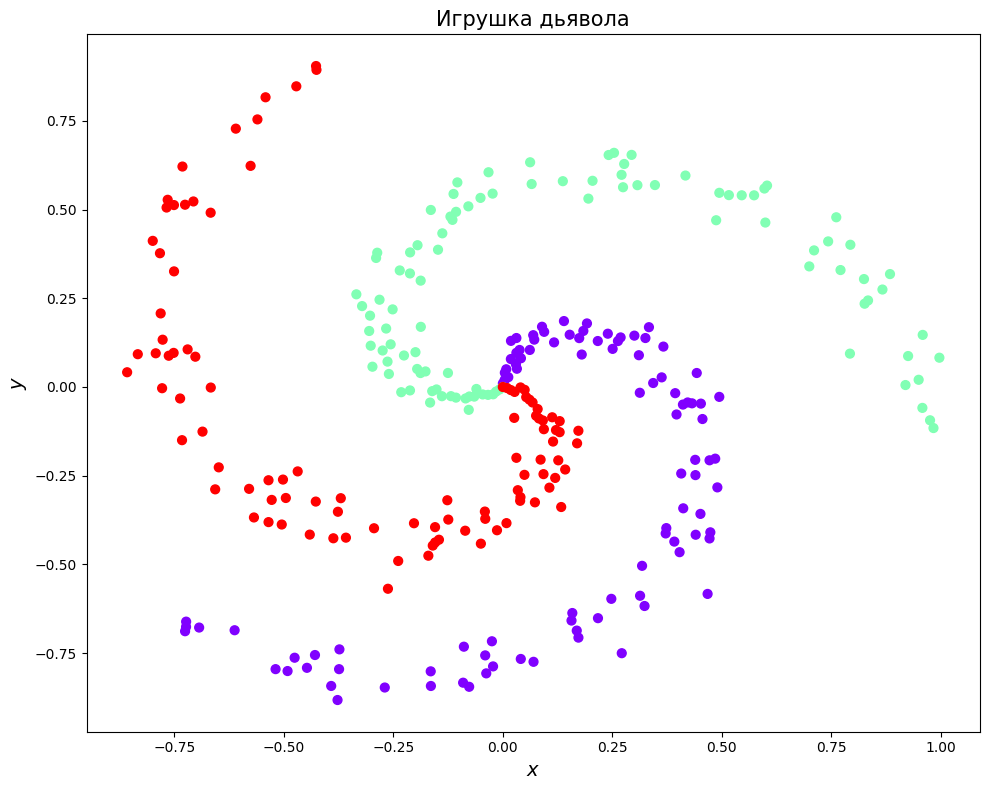

In [2]:
np.random.seed(42)

N = 100
D = 2
K = 3
X = np.zeros((N * K, D))
y = np.zeros(N * K, dtype="uint8")

for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2
    X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y[ix] = j

plt.figure(figsize=(10, 8))
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.rainbow)
plt.title("Игрушка дьявола", fontsize=15)
plt.xlabel("$x$", fontsize=14)
plt.ylabel("$y$", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig01_spiral.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
X_var = torch.autograd.Variable(torch.FloatTensor(X))
y_var = torch.autograd.Variable(torch.LongTensor(y.astype(np.int64)))

print(X_var.data.shape, y_var.data.shape)

torch.Size([300, 2]) torch.Size([300])


In [4]:
N, D_in, H, D_out = 64, 2, 100, 3

torch.manual_seed(0)

two_layer_net = nn.Sequential(
    nn.Linear(D_in, H),
    nn.ReLU(),
    nn.Linear(H, D_out),
)
two_layer_net

Sequential(
  (0): Linear(in_features=2, out_features=100, bias=True)
  (1): ReLU()
  (2): Linear(in_features=100, out_features=3, bias=True)
)

In [5]:
loss_fn = nn.CrossEntropyLoss(reduction="sum")

learning_rate = 1e-4
optimizer = torch.optim.SGD(two_layer_net.parameters(), lr=learning_rate)

for t in range(500):
    y_pred = two_layer_net(X_var)
    loss = loss_fn(y_pred, y_var)

    if t % 100 == 0:
        print(t, round(loss.item(), 4))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("Итоговый loss:", round(loss.item(), 4))

0 321.3454
100 245.1217
200 224.9441
300 215.4999
400 209.2179


Итоговый loss: 204.1377


In [6]:
with torch.no_grad():
    pred_example = two_layer_net(X_var).argmax(dim=1).numpy()

acc_example = accuracy_score(y, pred_example)
print("Accuracy:", round(acc_example, 4))
print("Матрица ошибок:\n", confusion_matrix(y, pred_example))

Accuracy: 0.5733
Матрица ошибок:
 [[59 33  8]
 [ 3 58 39]
 [39  6 55]]


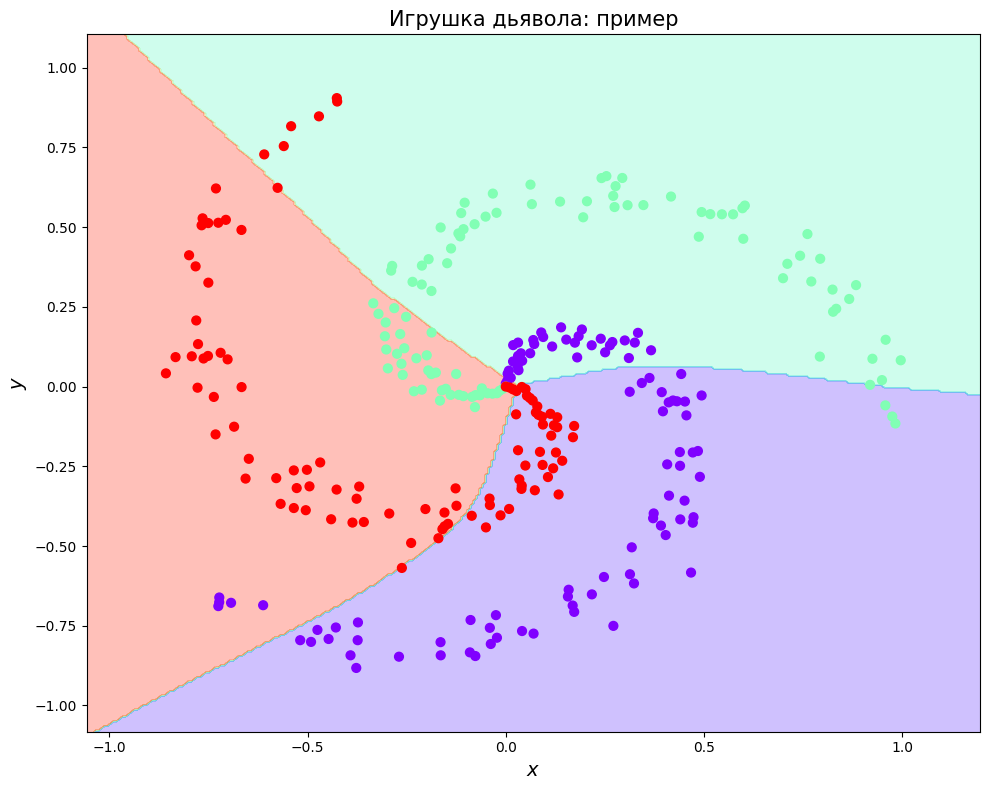

In [7]:
def plot_spiral_boundary(model, X, y, title, filename, mean=None, std=None):
    x_min, x_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
    y_min, y_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

    if mean is not None:
        grid = (grid - torch.tensor(mean, dtype=torch.float32)) / torch.tensor(std, dtype=torch.float32)

    with torch.no_grad():
        zz = model(grid).argmax(dim=1).numpy().reshape(xx.shape)

    plt.figure(figsize=(10, 8))
    plt.contourf(xx, yy, zz, cmap=plt.cm.rainbow, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.rainbow)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(title, fontsize=15)
    plt.xlabel("$x$", fontsize=14)
    plt.ylabel("$y$", fontsize=14)
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()


plot_spiral_boundary(two_layer_net, X, y, "Игрушка дьявола: пример",
                     "figures/fig02_example_boundary.png")

## Индивидуальное задание 1. Более эффективный MLP

In [8]:
mean = X.mean(axis=0, keepdims=True)
std = X.std(axis=0, keepdims=True)
X_std = (X - mean) / std

X_std_t = torch.tensor(X_std, dtype=torch.float32)
y_t = torch.tensor(y.astype(np.int64))

torch.manual_seed(0)

best_net = nn.Sequential(
    nn.Linear(D_in, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, D_out),
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(best_net.parameters(), lr=0.01)

losses = []
for t in range(3000):
    logits = best_net(X_std_t)
    loss = loss_fn(logits, y_t)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print("loss в начале:", round(losses[0], 4))
print("loss в конце:", round(losses[-1], 5))

loss в начале: 1.0805
loss в конце: 0.01114


In [9]:
with torch.no_grad():
    pred_best = best_net(X_std_t).argmax(dim=1).numpy()

acc_best = accuracy_score(y, pred_best)
print("Accuracy:", round(acc_best, 4))
print("Матрица ошибок:\n", confusion_matrix(y, pred_best))

Accuracy: 0.9933
Матрица ошибок:
 [[ 99   1   0]
 [  0 100   0]
 [  0   1  99]]


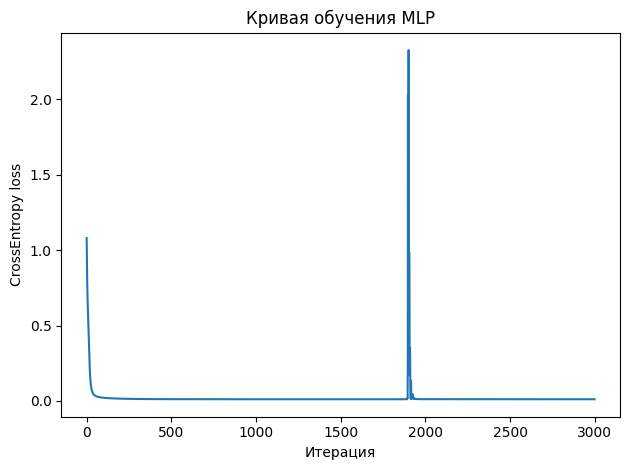

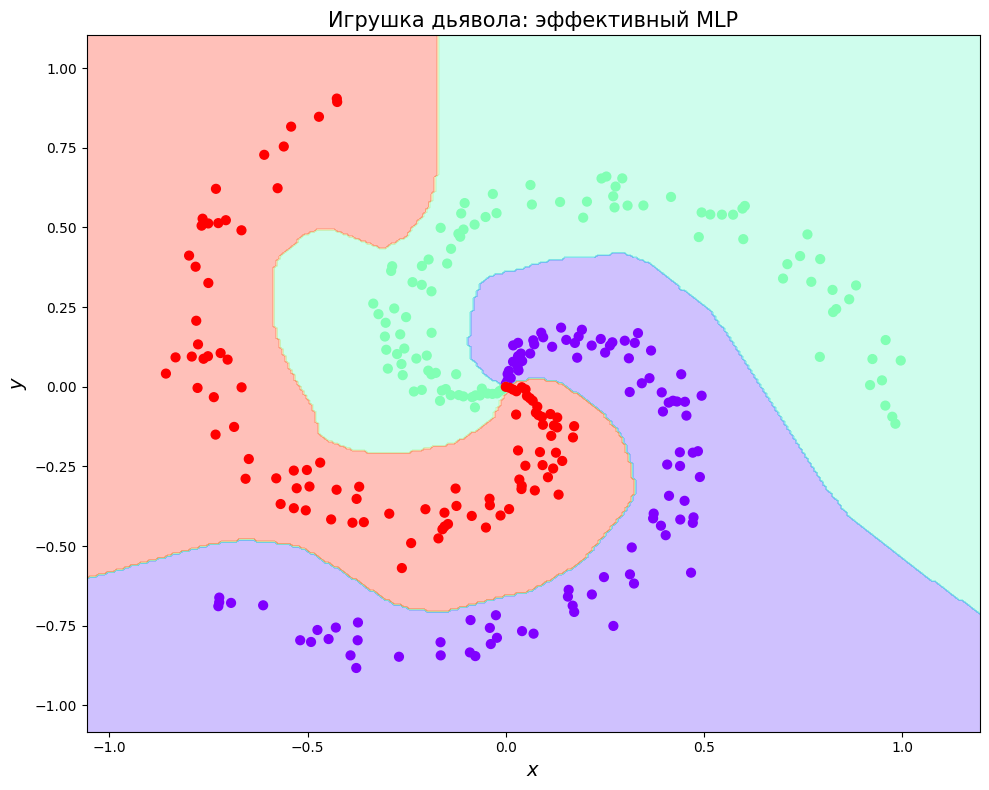

In [10]:
plt.plot(losses)
plt.xlabel("Итерация")
plt.ylabel("CrossEntropy loss")
plt.title("Кривая обучения MLP")
plt.tight_layout()
plt.savefig("figures/fig03_best_loss.png", dpi=150, bbox_inches="tight")
plt.show()

plot_spiral_boundary(best_net, X, y, "Игрушка дьявола: эффективный MLP",
                     "figures/fig04_best_boundary.png", mean=mean, std=std)

In [11]:
comparison = pd.DataFrame({
    "Модель": [
        "Пример: 1 скрытый слой, SGD, lr=1e-4, 500",
        "Эффективный MLP: 2 скрытых слоя, Adam, lr=0.01, 3000",
    ],
    "Accuracy": [acc_example, acc_best],
})
comparison

,Модель,Accuracy
0,"Пример: 1 скрытый слой, SGD, lr=1e-4, 500",0.573333
1,"Эффективный MLP: 2 скрытых слоя, Adam, lr=0.01...",0.993333


## Индивидуальное задание 2. CommitSuite

In [12]:
url = "https://raw.githubusercontent.com/security-pride/CommitSuite/master/Ten-category-eval_dataset/all_data.json"
path = "datasets/CommitSuite/all_data.json"

if not os.path.exists(path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    urllib.request.urlretrieve(url, path)

with open(path, encoding="utf-8") as f:
    commits = json.load(f)

df = pd.DataFrame(commits)
print("Размер набора:", df.shape)
print(df["message_type"].value_counts())
df[["message_type", "description"]].head()

Размер набора: (1160, 17)
message_type
build       116
chore       116
ci          116
docs        116
feat        116
fix         116
perf        116
refactor    116
style       116
test        116
Name: count, dtype: int64


,message_type,description
0,build,bump to version v0.16.0-rc
1,build,Remove debugger uapi symbols that have been de...
2,build,bump version to v0.18.0
3,build,hotfix release
4,build,add utilities to get genesis and bootstrapper ...


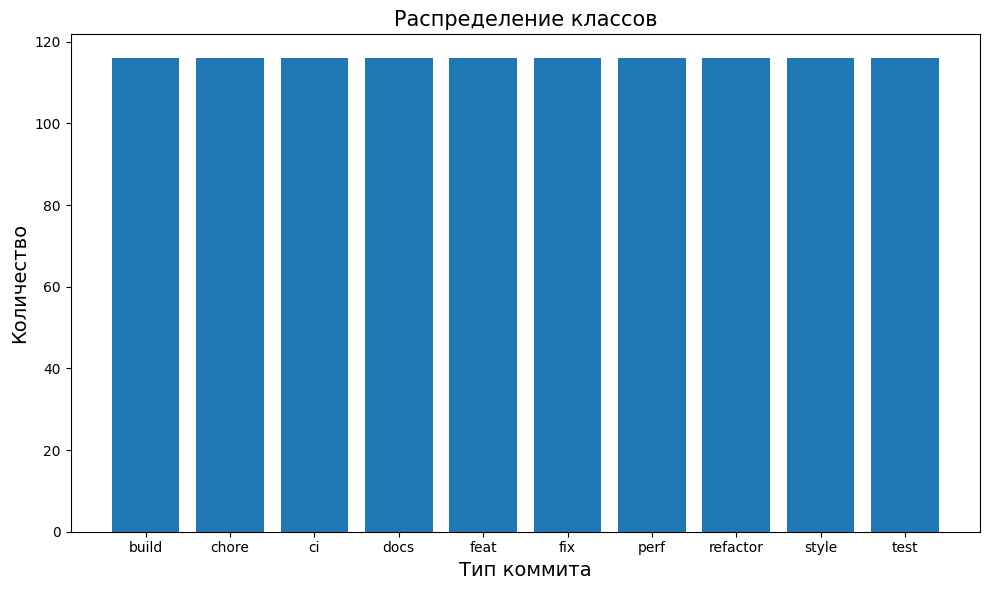

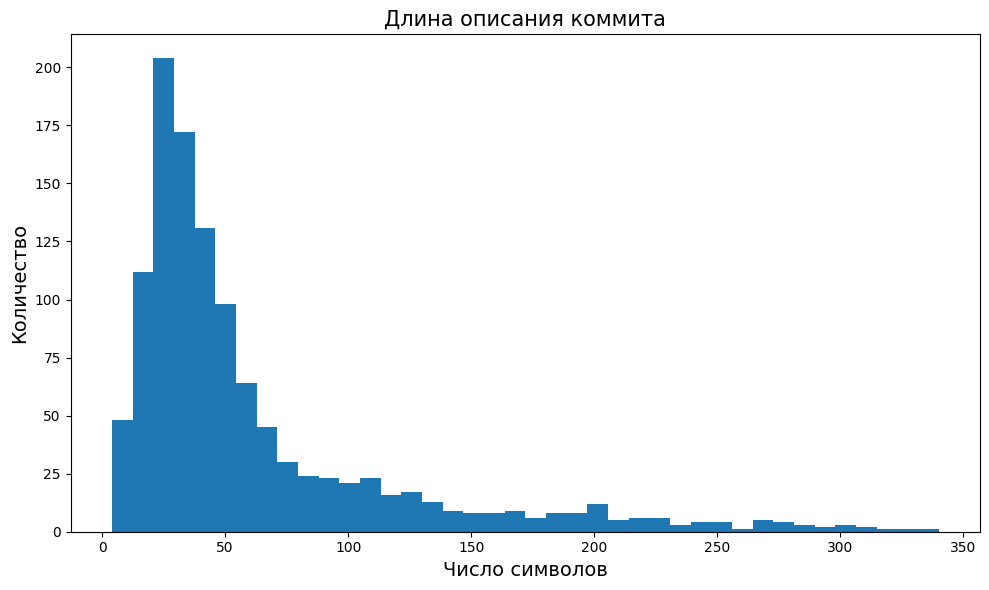

In [13]:
classes = sorted(df["message_type"].unique())

counts = df["message_type"].value_counts().reindex(classes)
plt.figure(figsize=(10, 6))
plt.bar(classes, counts.values)
plt.title("Распределение классов", fontsize=15)
plt.xlabel("Тип коммита", fontsize=14)
plt.ylabel("Количество", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig05_commit_classes.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 6))
plt.hist(df["description"].str.len(), bins=40)
plt.title("Длина описания коммита", fontsize=15)
plt.xlabel("Число символов", fontsize=14)
plt.ylabel("Количество", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig06_commit_length.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
def paths_text(files):
    if not isinstance(files, list):
        return ""
    return " ".join(f"{f.get('filename', '')} {f.get('change_type', '')}" for f in files)


df["text_desc"] = df["description"].fillna("").astype(str)
df["text_paths"] = df["modified_files"].map(paths_text)


def structural_features(d):
    out = pd.DataFrame(index=d.index)
    out["msg_len"] = d["msg"].fillna("").str.len()
    out["desc_len"] = d["description"].fillna("").str.len()
    out["words"] = d["description"].fillna("").str.split().map(len)
    out["why"] = d["why"].fillna(0).astype(float)
    out["what"] = d["what"].fillna(0).astype(float)
    out["n_files"] = d["modified_files"].map(lambda x: len(x) if isinstance(x, list) else 0)
    out["added"] = d["modified_files"].map(
        lambda x: sum(f.get("added_lines", 0) or 0 for f in x) if isinstance(x, list) else 0)
    out["deleted"] = d["modified_files"].map(
        lambda x: sum(f.get("deleted_lines", 0) or 0 for f in x) if isinstance(x, list) else 0)
    out["n_issues"] = d["issues"].map(lambda x: len(x) if isinstance(x, list) else 0)
    out["n_prs"] = d["prs"].map(lambda x: len(x) if isinstance(x, list) else 0)
    out["strict"] = d["strict_ccs"].fillna(0).astype(float)
    return out


S = structural_features(df).values.astype("float32")
labels = df["message_type"].values

idx_train, idx_test = train_test_split(
    np.arange(len(df)), test_size=0.2, random_state=42, stratify=labels)

y_train = pd.Categorical(labels[idx_train], categories=classes).codes
y_test = pd.Categorical(labels[idx_test], categories=classes).codes

vec_word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=6000, sublinear_tf=True)
vec_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, max_features=8000, sublinear_tf=True)
vec_path = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, max_features=6000, sublinear_tf=True)

X_word_train = vec_word.fit_transform(df["text_desc"].values[idx_train])
X_word_test = vec_word.transform(df["text_desc"].values[idx_test])
X_char_train = vec_char.fit_transform(df["text_desc"].values[idx_train])
X_char_test = vec_char.transform(df["text_desc"].values[idx_test])
X_path_train = vec_path.fit_transform(df["text_paths"].values[idx_train])
X_path_test = vec_path.transform(df["text_paths"].values[idx_test])

X_train = hstack([X_word_train, X_char_train, X_path_train]).tocsr()
X_test = hstack([X_word_test, X_char_test, X_path_test]).tocsr()

mean_s = S[idx_train].mean(axis=0, keepdims=True)
std_s = S[idx_train].std(axis=0, keepdims=True) + 1e-8
X_train = hstack([X_train, csr_matrix((S[idx_train] - mean_s) / std_s)]).toarray().astype("float32")
X_test = hstack([X_test, csr_matrix((S[idx_test] - mean_s) / std_s)]).toarray().astype("float32")

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (928, 15245)
Тестовая выборка: (232, 15245)


In [15]:
torch.manual_seed(0)

commit_net = nn.Sequential(
    nn.Linear(X_train.shape[1], 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, len(classes)),
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(commit_net.parameters(), lr=1e-3, weight_decay=1e-4)

X_train_t = torch.tensor(X_train)
y_train_t = torch.tensor(y_train, dtype=torch.long)

batch_size = 64
losses = []
for epoch in range(60):
    perm = torch.randperm(len(X_train_t))
    commit_net.train()
    epoch_loss = 0.0

    for i in range(0, len(X_train_t), batch_size):
        idx = perm[i:i + batch_size]
        logits = commit_net(X_train_t[idx])
        loss = loss_fn(logits, y_train_t[idx])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(idx)

    losses.append(epoch_loss / len(X_train_t))

print("loss в начале:", round(losses[0], 4))
print("loss в конце:", round(losses[-1], 4))

loss в начале: 2.282
loss в конце: 0.0235


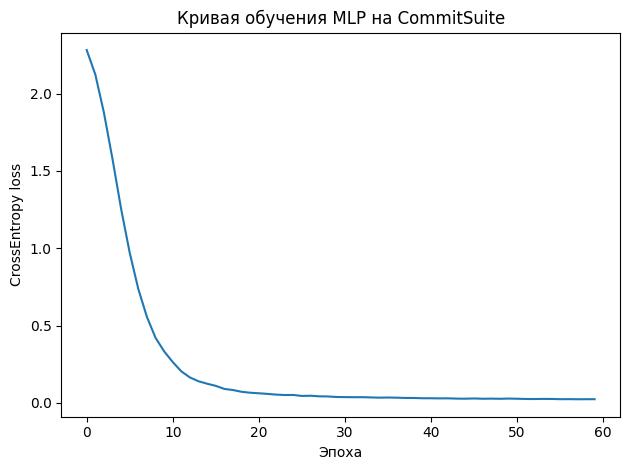

In [17]:
plt.plot(losses)
plt.xlabel("Эпоха")
plt.ylabel("CrossEntropy loss")
plt.title("Кривая обучения MLP на CommitSuite")
plt.tight_layout()
plt.savefig("figures/fig08_commit_loss.png", dpi=150, bbox_inches="tight")
plt.show()

Accuracy: 0.5474
Macro F1: 0.5447
              precision    recall  f1-score   support

       build      0.833     0.652     0.732        23
       chore      0.391     0.391     0.391        23
          ci      0.690     0.870     0.769        23
        docs      0.600     0.625     0.612        24
        feat      0.440     0.478     0.458        23
         fix      0.227     0.217     0.222        23
        perf      0.708     0.708     0.708        24
    refactor      0.407     0.478     0.440        23
       style      0.562     0.391     0.462        23
        test      0.652     0.652     0.652        23

    accuracy                          0.547       232
   macro avg      0.551     0.546     0.545       232
weighted avg      0.552     0.547     0.546       232



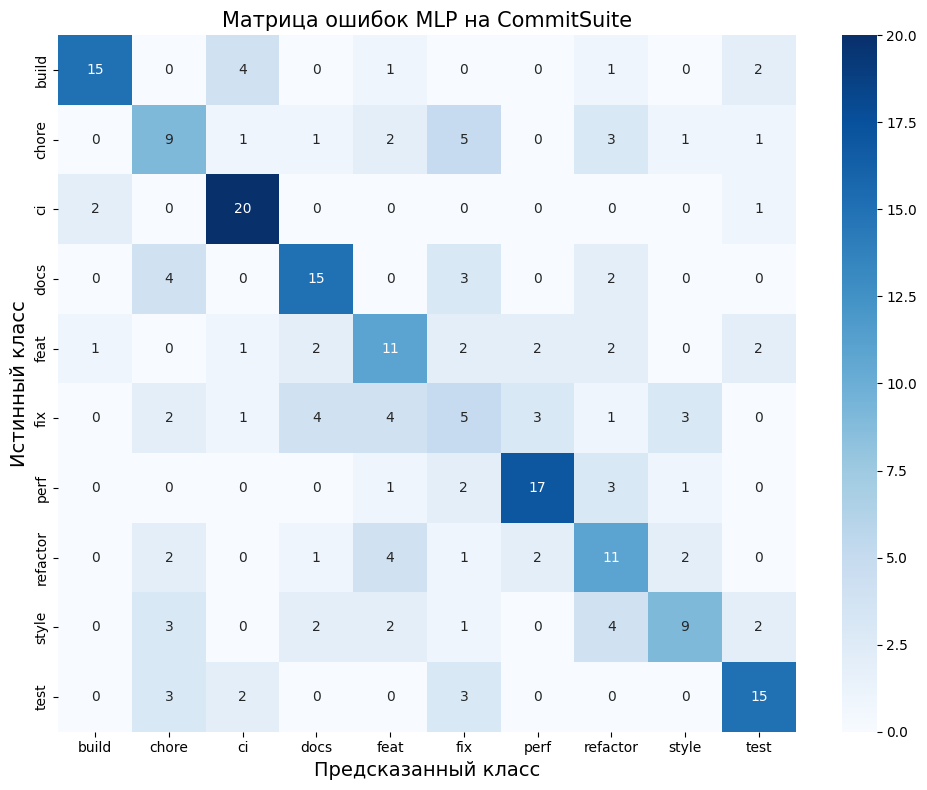

In [16]:
commit_net.eval()
with torch.no_grad():
    pred = commit_net(torch.tensor(X_test)).argmax(dim=1).numpy()

acc_commit = accuracy_score(y_test, pred)
f1_commit = f1_score(y_test, pred, average="macro")

print("Accuracy:", round(acc_commit, 4))
print("Macro F1:", round(f1_commit, 4))
print(classification_report(y_test, pred, target_names=classes, digits=3))

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("Матрица ошибок MLP на CommitSuite", fontsize=15)
plt.xlabel("Предсказанный класс", fontsize=14)
plt.ylabel("Истинный класс", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig07_commit_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

### Доп. сравнение: линейная модель

In [18]:
torch.manual_seed(0)

linear_net = nn.Sequential(
    nn.Linear(X_train.shape[1], len(classes))
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(linear_net.parameters(), lr=1e-3, weight_decay=1e-4)

for epoch in range(60):
    perm = torch.randperm(len(X_train_t))
    linear_net.train()

    for i in range(0, len(X_train_t), batch_size):
        idx = perm[i:i + batch_size]
        logits = linear_net(X_train_t[idx])
        loss = loss_fn(logits, y_train_t[idx])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

linear_net.eval()
with torch.no_grad():
    pred_linear = linear_net(torch.tensor(X_test)).argmax(dim=1).numpy()

acc_linear = accuracy_score(y_test, pred_linear)
f1_linear = f1_score(y_test, pred_linear, average="macro")
print("Accuracy:", round(acc_linear, 4))
print("Macro F1:", round(f1_linear, 4))

Accuracy: 0.4871
Macro F1: 0.4872


### Доп. сравнение: модель с двумя скрытыми слоями

In [19]:
torch.manual_seed(0)

deep_net = nn.Sequential(
    nn.Linear(X_train.shape[1], 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(64, len(classes)),
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(deep_net.parameters(), lr=1e-3, weight_decay=1e-4)

for epoch in range(60):
    perm = torch.randperm(len(X_train_t))
    deep_net.train()

    for i in range(0, len(X_train_t), batch_size):
        idx = perm[i:i + batch_size]
        logits = deep_net(X_train_t[idx])
        loss = loss_fn(logits, y_train_t[idx])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

deep_net.eval()
with torch.no_grad():
    pred_deep = deep_net(torch.tensor(X_test)).argmax(dim=1).numpy()

acc_deep = accuracy_score(y_test, pred_deep)
f1_deep = f1_score(y_test, pred_deep, average="macro")
print("Accuracy:", round(acc_deep, 4))
print("Macro F1:", round(f1_deep, 4))

Accuracy: 0.4741
Macro F1: 0.4652


In [20]:
results = pd.DataFrame({
    "Задача": ["Игрушка дьявола", "Игрушка дьявола", "CommitSuite", "CommitSuite", "CommitSuite"],
    "Модель": [
        "Пример: 1 скрытый слой, SGD, lr=1e-4, 500",
        "Эффективный MLP: 2 скрытых слоя, Adam, lr=0.01, 3000",
        "Линейная модель: Adam, lr=1e-3, 60",
        "Эффективный MLP: 1 скрытый слой, Adam, lr=1e-3, 60",
        "MLP: 2 скрытых слоя, Adam, lr=1e-3, 60",
    ],
    "Accuracy": [acc_example, acc_best, acc_linear, acc_commit, acc_deep],
})
results

,Задача,Модель,Accuracy
0,Игрушка дьявола,"Пример: 1 скрытый слой, SGD, lr=1e-4, 500",0.573333
1,Игрушка дьявола,"Эффективный MLP: 2 скрытых слоя, Adam, lr=0.01...",0.993333
2,CommitSuite,"Линейная модель: Adam, lr=1e-3, 60",0.487069
3,CommitSuite,"Эффективный MLP: 1 скрытый слой, Adam, lr=1e-3...",0.547414
4,CommitSuite,"MLP: 2 скрытых слоя, Adam, lr=1e-3, 60",0.474138
